# Desafio: regularização
Vamos comparar Ridge, Lasso e ElasticNet para prever um valor numérico a partir dos dados de pacientes. Escolheremos a intensidade da regularização usando a validação e avaliaremos o modelo no teste ao final.

## 1. Importar as bibliotecas
Carregamos as ferramentas para organizar os dados, treinar os modelos e mostrar os resultados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import root_mean_squared_error, r2_score

SEED = 42
SCORING = "neg_root_mean_squared_error"
print("Versão do scikit-learn:", sklearn.__version__)

Versão do scikit-learn: 1.8.0


## 2. Carregar e separar os dados
`X` contém as características dos pacientes e `y`, as respostas conhecidas. Reservamos 20% dos exemplos para o teste final e usamos o restante para treinar e escolher o modelo.

In [2]:
#carregando o dataset sem padronização prévia
X, y = load_diabetes(return_X_y=True, as_frame=True, scaled=False)

#separando treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Dataset:", X.shape)
print("Treino:", X_treino.shape, "| Teste reservado:", X_teste.shape)

Dataset: (442, 10)
Treino: (353, 10) | Teste reservado: (89, 10)


## 3. Preparar o Pipeline e a validação
O Pipeline padroniza as características dentro de cada treino. Dividimos os dados de treino em cinco partes para comparar as configurações: em cada rodada, quatro treinam e uma valida.

In [3]:
def criar_pipeline(modelo):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", modelo)
    ])


cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

## 4. Testar vários valores de alpha
Com essas divisões, experimentamos diferentes intensidades de regularização nos três modelos. Guardamos o RMSE médio de validação e seu desvio padrão; quanto menor o RMSE, melhor.

In [4]:
#criando os modelos e as grades de alpha
modelos = {
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=50000),
    "ElasticNet": ElasticNet(l1_ratio=0.5, max_iter=50000)
}
grades = {
    "Ridge": np.logspace(-3, 3, 61),
    "Lasso": np.logspace(-3, 1.5, 46),
    "ElasticNet": np.logspace(-3, 1.5, 46)
}
curvas = {}

for nome, estimador in modelos.items():
    busca = GridSearchCV(
        criar_pipeline(estimador),
        {"modelo__alpha": grades[nome]},
        cv=cv, scoring=SCORING
    )
    busca.fit(X_treino, y_treino)
    resultados = busca.cv_results_
    curvas[nome] = pd.DataFrame({
        "alpha": np.asarray(resultados["param_modelo__alpha"], dtype=float),
        "RMSE médio": -resultados["mean_test_score"],
        "Desvio padrão": resultados["std_test_score"]
    }).sort_values("alpha").reset_index(drop=True)

    indice_minimo = curvas[nome]["RMSE médio"].idxmin()
    if indice_minimo in [0, len(curvas[nome]) - 1]:
        print(f"Atenção: mínimo do {nome} na borda da grade; investigue um intervalo maior.")
    else:
        print(f"{nome}: mínimo dentro da grade.")

Ridge: mínimo dentro da grade.
Lasso: mínimo dentro da grade.
ElasticNet: mínimo dentro da grade.


## 5. Aplicar a regra de um desvio padrão
Para cada modelo, somamos o menor RMSE médio ao desvio padrão daquela configuração. Escolhemos o maior alpha cujo erro médio fique até esse limite, aceitando mais regularização com erro próximo do mínimo.

In [5]:
def selecionar_um_dp(tabela):
    melhor = tabela.loc[tabela["RMSE médio"].idxmin()]
    limite = melhor["RMSE médio"] + melhor["Desvio padrão"]
    aceitos = tabela[tabela["RMSE médio"] <= limite]
    escolhido = aceitos.loc[aceitos["alpha"].idxmax()]
    return melhor, limite, escolhido


linhas = []
for nome, tabela in curvas.items():
    melhor, limite, escolhido = selecionar_um_dp(tabela)
    linhas.append({
        "Modelo": nome,
        "Alpha mínimo": melhor["alpha"],
        "RMSE-CV mínimo": melhor["RMSE médio"],
        "DP no mínimo": melhor["Desvio padrão"],
        "Limite de 1 dp": limite,
        "Alpha de 1 dp": escolhido["alpha"],
        "RMSE-CV de 1 dp": escolhido["RMSE médio"]
    })

resumo = pd.DataFrame(linhas)
display(resumo.round(4))

,Modelo,Alpha mínimo,RMSE-CV mínimo,DP no mínimo,Limite de 1 dp,Alpha de 1 dp,RMSE-CV de 1 dp
0,Ridge,0.7943,55.3741,2.3727,57.7468,199.5262,57.1881
1,Lasso,0.1585,55.3489,2.3449,57.6937,7.9433,57.0803
2,ElasticNet,0.0063,55.3733,2.3726,57.7459,1.2589,57.1728


## 6. Gráficos de RMSE-CV por alpha
Agora visualizamos os erros calculados: o eixo horizontal mostra alpha e o vertical, o RMSE médio. A curva mais baixa indica menor erro de validação.

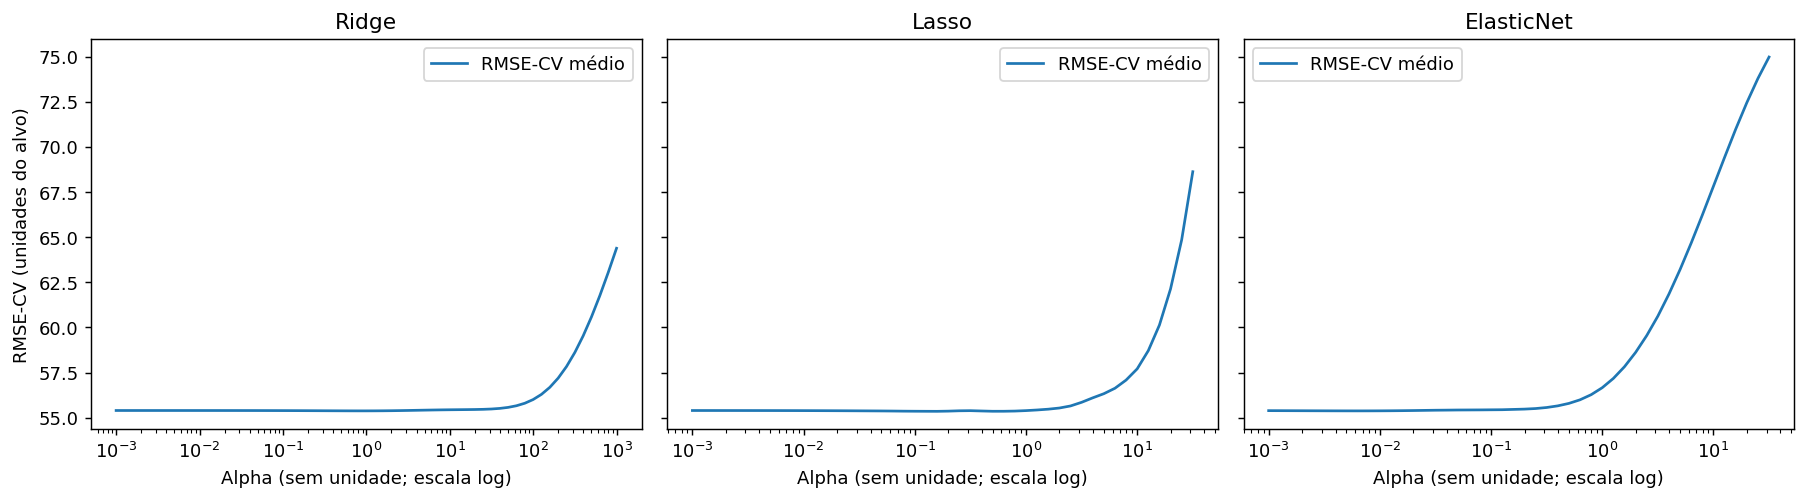

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for eixo, (nome, tabela) in zip(eixos, curvas.items()):
    eixo.plot(tabela["alpha"], tabela["RMSE médio"], label="RMSE-CV médio")
    eixo.set_xscale("log")
    eixo.set_xlabel("Alpha (sem unidade; escala log)")
    eixo.set_title(nome)
    eixo.legend()

eixos[0].set_ylabel("RMSE-CV (unidades do alvo)")
plt.tight_layout()
plt.show()

## 7. Contar coeficientes zerados em cinco alphas
Além do erro, observamos como a regularização afeta os pesos das características. Para cinco valores de alpha, contamos quais coeficientes ficaram zero e deixaram de contribuir para a previsão.

In [7]:
alphas_inspecao = [0.001, 0.01, 0.1, 1.0, 10.0]
linhas_zeros = []

for nome, estimador in modelos.items():
    for alpha in alphas_inspecao:
        pipeline = criar_pipeline(sklearn.base.clone(estimador))
        pipeline.set_params(modelo__alpha=alpha)
        pipeline.fit(X_treino, y_treino)
        coeficientes = pipeline.named_steps["modelo"].coef_
        zerados = X_treino.columns[coeficientes == 0].tolist()
        linhas_zeros.append({
            "Modelo": nome,
            "Alpha": alpha,
            "Coeficientes zerados": len(zerados),
            "Variáveis zeradas": ", ".join(zerados) if zerados else "Nenhuma"
        })

tabela_zeros = pd.DataFrame(linhas_zeros)
display(tabela_zeros)

,Modelo,Alpha,Coeficientes zerados,Variáveis zeradas
0,Ridge,0.001,0,Nenhuma
1,Ridge,0.010,0,Nenhuma
2,Ridge,0.100,0,Nenhuma
3,Ridge,1.000,0,Nenhuma
4,Ridge,10.000,0,Nenhuma
5,Lasso,0.001,0,Nenhuma
6,Lasso,0.010,0,Nenhuma
7,Lasso,0.100,0,Nenhuma
8,Lasso,1.000,1,s2
9,Lasso,10.000,6,"age, sex, s1, s2, s4, s6"


## 8. Verificar a estabilidade do Lasso com três sementes
Para verificar se os mesmos coeficientes continuam zerando, mantemos o alpha escolhido e variamos as divisões do treino com três sementes. A tabela conta quantas vezes cada coeficiente zerou nos 15 ajustes.

In [8]:
alpha_lasso = float(resumo.loc[resumo["Modelo"] == "Lasso", "Alpha de 1 dp"].iloc[0])
sementes = [7, 21, 42]
contagens_zeros = {}

for semente in sementes:
    cv_semente = KFold(n_splits=5, shuffle=True, random_state=semente)
    contagem = np.zeros(X_treino.shape[1], dtype=int)
    for indices_ajuste, _ in cv_semente.split(X_treino):
        pipeline = criar_pipeline(Lasso(alpha=alpha_lasso, max_iter=50000))
        pipeline.fit(X_treino.iloc[indices_ajuste], y_treino.iloc[indices_ajuste])
        contagem += (pipeline.named_steps["modelo"].coef_ == 0).astype(int)
    contagens_zeros[f"Semente {semente} (de 5)"] = contagem

estabilidade = pd.DataFrame(contagens_zeros, index=X_treino.columns)
estabilidade.index.name = "Variável"
estabilidade["Total (de 15)"] = estabilidade.sum(axis=1)
estabilidade["Frequência de zero (%)"] = 100 * estabilidade["Total (de 15)"] / 15
print(f"Alpha fixo do Lasso: {alpha_lasso:.6g}")
display(estabilidade.round(2))

Alpha fixo do Lasso: 7.94328


,Semente 7 (de 5),Semente 21 (de 5),Semente 42 (de 5),Total (de 15),Frequência de zero (%)
Variável,,,,,
age,5,5,5,15,100.00
sex,5,5,5,15,100.00
bmi,0,0,0,0,0.00
bp,0,0,0,0,0.00
s1,5,5,5,15,100.00
s2,5,5,5,15,100.00
s3,0,0,0,0,0.00
s4,5,5,5,15,100.00
s5,0,0,0,0,0.00


## 9. Escolher o modelo
Entre os três candidatos da regra de um desvio padrão, escolhemos o de menor RMSE-CV e o treinamos com todo o conjunto de treino. O teste ainda não participa dessa escolha.

In [9]:
selecionado = resumo.loc[resumo["RMSE-CV de 1 dp"].idxmin()]
nome_final = selecionado["Modelo"]
alpha_final = float(selecionado["Alpha de 1 dp"])

modelo_final = criar_pipeline(sklearn.base.clone(modelos[nome_final]))
modelo_final.set_params(modelo__alpha=alpha_final)
modelo_final.fit(X_treino, y_treino)

print("Modelo escolhido:", nome_final)
print(f"Alpha escolhido: {alpha_final:.6g}")
print(f"RMSE-CV da configuração: {selecionado['RMSE-CV de 1 dp']:.3f}")

Modelo escolhido: Lasso
Alpha escolhido: 7.94328
RMSE-CV da configuração: 57.080


## 10. Avaliar no teste
Com a escolha definida, prevemos as respostas dos pacientes reservados e calculamos RMSE e R². Essa é a avaliação final: não usamos seu resultado para mudar o modelo.

In [10]:
#usando o teste somente depois de definir o modelo
y_previsto = modelo_final.predict(X_teste)
rmse_teste = root_mean_squared_error(y_teste, y_previsto)
r2_teste = r2_score(y_teste, y_previsto)

resultado_final = pd.DataFrame([{
    "Modelo": nome_final,
    "Alpha": alpha_final,
    "RMSE-CV": selecionado["RMSE-CV de 1 dp"],
    "RMSE no teste": rmse_teste,
    "R² no teste": r2_teste
}])
display(resultado_final.round(4))

,Modelo,Alpha,RMSE-CV,RMSE no teste,R² no teste
0,Lasso,7.9433,57.0803,53.7991,0.4537
